# Nuclei segmentation and quantification in H&E histopathology

U-Net segmentation followed by watershed instance separation, on the MoNuSeg (MICCAI 2018) benchmark.
Validation: 0.762 Dice, 0.651 IoU on 6 held-out slides. Nucleus count error 26.7% -> 10.0% after watershed.

## 1. Data

30 H&E slides at 1000x1000, 40x magnification, from TCGA across seven organs.
Annotations are per-nucleus polygon outlines in Aperio ImageScope XML.
The pairing check below guards against an image with no matching annotation file,
which would silently train on an all-zero mask.

In [20]:
!wget -q -O monuseg.zip "https://zenodo.org/records/1473148/files/MoNuSeg_Training_Data.zip?download=1"
!unzip -q -o monuseg.zip -d data

from pathlib import Path

root = next(Path("data").glob("*Training Data*"))
images = sorted((root / "Tissue images").glob("*.tif"))
annots = sorted((root / "Annotations").glob("*.xml"))

print(len(images), len(annots), {p.stem for p in images} == {p.stem for p in annots})

30 30 True


In [21]:
from PIL import Image
import numpy as np

img = np.array(Image.open(images[0]))
print(img.shape, img.dtype, img.min(), img.max())

import xml.etree.ElementTree as ET

tree = ET.parse(annots[0])
for el in list(tree.iter())[:10]:
    print(el.tag, list(el.attrib)[:3])

print("regions:", len(tree.findall(".//Region")))
print("vertices in region 0:", len(tree.findall(".//Region")[0].findall(".//Vertex")))

(1000, 1000, 3) uint8 8 255
Annotations ['MicronsPerPixel']
Annotation ['Id', 'Name', 'ReadOnly']
Attributes []
Attribute ['Name', 'Id', 'Value']
Regions []
RegionAttributeHeaders []
AttributeHeader ['Id', 'Name', 'ColumnWidth']
AttributeHeader ['Id', 'Name', 'ColumnWidth']
AttributeHeader ['Id', 'Name', 'ColumnWidth']
AttributeHeader ['Id', 'Name', 'ColumnWidth']
regions: 480
vertices in region 0: 453


In [22]:
counts = [len(r.findall(".//Vertex")) for r in tree.findall(".//Region")]
print("vertices per region — min/median/max:", min(counts), int(np.median(counts)), max(counts))

total = sum(len(ET.parse(a).findall(".//Region")) for a in annots)
print("total nuclei across 30 files:", total)

vertices per region — min/median/max: 73 253 673
total nuclei across 30 files: 16966


In [23]:
from collections import Counter

per_file = {a.stem: len(ET.parse(a).findall(".//Region")) for a in annots}
print(sorted(per_file.values()))

t = ET.parse(annots[0])
print("Annotation elements:", len(t.findall(".//Annotation")))
print(Counter(tuple(sorted(r.attrib)) for r in t.findall(".//Region")))
print(t.findall(".//Region")[0].attrib)

[294, 314, 329, 342, 342, 354, 356, 357, 359, 363, 363, 378, 390, 398, 401, 405, 424, 433, 440, 442, 445, 448, 472, 480, 557, 1076, 1165, 1391, 1585, 1863]
Annotation elements: 1
Counter({('Analyze', 'Area', 'AreaMicrons', 'DisplayId', 'Id', 'ImageFocus', 'ImageLocation', 'InputRegionId', 'Length', 'LengthMicrons', 'NegativeROA', 'Selected', 'Text', 'Type', 'Zoom'): 480})
{'Id': '2', 'Type': '0', 'Zoom': '5', 'Selected': '0', 'ImageLocation': '', 'ImageFocus': '0', 'Length': '126.0', 'Area': '1049.3', 'LengthMicrons': '31.8', 'AreaMicrons': '66.6', 'Text': '', 'NegativeROA': '0', 'InputRegionId': '0', 'Analyze': '1', 'DisplayId': '2'}


## 2. Masks from polygon annotations

Each Region in the XML is one nucleus, stored as a vertex list. Polygons are
rasterised twice: filled with 1 for a binary semantic mask, and filled with an
incrementing integer for an instance mask where every nucleus has its own id.

The semantic mask answers "nucleus or not"; only the instance mask can be counted.

Masks are verified two ways below: visually by overlaying contours on the tile,
and physically by checking mean nucleus area against the 0.252 um/px scale
(888.8 px -> ~8.5 um equivalent diameter, the correct biological size).

In [24]:
import numpy as np
from PIL import Image, ImageDraw

regions = ET.parse(annots[0]).findall(".//Region")
polys = [[(float(v.get("X")), float(v.get("Y"))) for v in r.findall(".//Vertex")] for r in regions]

sem_img = Image.new("L", (1000, 1000), 0)
inst_img = Image.new("I", (1000, 1000), 0)
draw_sem = ImageDraw.Draw(sem_img)
draw_inst = ImageDraw.Draw(inst_img)

for i, p in enumerate(polys, start=1):
  draw_sem.polygon(p, fill=1)
  draw_inst.polygon(p, fill=i)

sem = np.array(sem_img, np.uint8)
inst = np.array(inst_img, np.int32)

print("semantic:", sem.shape, sem.dtype, "values:", np.unique(sem))
print("instances drawn:", inst.max(), "of", len(polys), "polygons")
print("nucleus pixel fraction:", round(float(sem.mean()), 4))

semantic: (1000, 1000) uint8 values: [0 1]
instances drawn: 480 of 480 polygons
nucleus pixel fraction: 0.4266


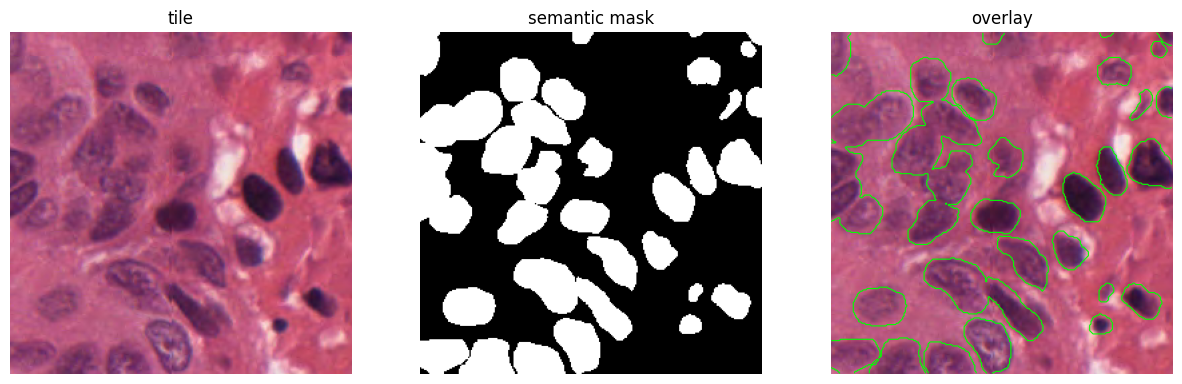

mean nucleus area (px): 888.8
image MicronsPerPixel: 0.252000


In [25]:
import matplotlib.pyplot as plt

img = np.array(Image.open(images[0]))
ys, xs = slice(300, 556), slice(300, 556)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img[ys, xs]); ax[0].set_title("tile"); ax[0].axis("off")
ax[1].imshow(sem[ys, xs], cmap="gray"); ax[1].set_title("semantic mask"); ax[1].axis("off")
ax[2].imshow(img[ys, xs]); ax[2].contour(sem[ys, xs], levels=[0.5], colors="lime", linewidths=0.8); ax[2].set_title("overlay"); ax[2].axis("off")
plt.show()

print("mean nucleus area (px):", round(float(sem.sum()) / inst.max(), 1))
print("image MicronsPerPixel:", ET.parse(annots[0]).getroot().get("MicronsPerPixel"))

## 3. Tiling and slide-level split

1000 is not divisible by 256. A stride of 256 would cover only 768 px per axis and
discard the remaining 232 px of every slide - 23% of the data. Offsets
[0, 248, 496, 744] cover the full 1000 with 8 px of overlap instead.

The train/validation split is **by slide, not by tile**. Tiles from one slide share
a patient, a staining batch and a scanner, and neighbouring tiles share pixels.
A random tile split would put near-duplicates on both sides and inflate the
validation score. The `slide overlap` print below must be an empty set.

In [26]:
from tqdm import tqdm

OFFSETS = [0, 248, 496, 744]

def masks_for(xml_path, size=1000):
    polys = [[(float(v.get("X")), float(v.get("Y"))) for v in r.findall(".//Vertex")]
             for r in ET.parse(xml_path).findall(".//Region")]
    sem_img = Image.new("L", (size, size), 0)
    inst_img = Image.new("I", (size, size), 0)
    draw_sem, draw_inst = ImageDraw.Draw(sem_img), ImageDraw.Draw(inst_img)
    for i, p in enumerate(polys, start=1):
        draw_sem.polygon(p, fill=1)
        draw_inst.polygon(p, fill=i)
    return np.array(sem_img, np.uint8), np.array(inst_img, np.int32)

tile_img, tile_sem, tile_inst, tile_slide = [], [], [], []

for ip, ap in tqdm(list(zip(images, annots)), desc="tiling"):
    assert ip.stem == ap.stem
    im = np.array(Image.open(ip).convert("RGB"))
    sm, it = masks_for(ap)
    for y in OFFSETS:
        for x in OFFSETS:
            tile_img.append(im[y:y+256, x:x+256])
            tile_sem.append(sm[y:y+256, x:x+256])
            tile_inst.append(it[y:y+256, x:x+256])
            tile_slide.append(ip.stem)

tile_img = np.stack(tile_img)
tile_sem = np.stack(tile_sem)

print(tile_img.shape, tile_sem.shape)
print("tiles:", len(tile_slide), "from", len(set(tile_slide)), "slides")
print("mean nucleus fraction:", round(float(tile_sem.mean()), 4))
print("empty tiles:", int((tile_sem.sum((1, 2)) == 0).sum()))

tiling: 100%|██████████| 30/30 [00:22<00:00,  1.35it/s]

(480, 256, 256, 3) (480, 256, 256)
tiles: 480 from 30 slides
mean nucleus fraction: 0.2459
empty tiles: 0


In [27]:
import random

slides = sorted(set(tile_slide))
random.Random(0).shuffle(slides)
val_slides = set(slides[:6])

train_idx = [i for i, s in enumerate(tile_slide) if s not in val_slides]
val_idx = [i for i, s in enumerate(tile_slide) if s in val_slides]

print("train tiles:", len(train_idx), " val tiles:", len(val_idx))
print("slide overlap:", set(tile_slide[i] for i in train_idx) & val_slides)
print("train nucleus fraction:", round(float(tile_sem[train_idx].mean()), 4))
print("val nucleus fraction:", round(float(tile_sem[val_idx].mean()), 4))

train tiles: 384  val tiles: 96
slide overlap: set()
train nucleus fraction: 0.2401
val nucleus fraction: 0.2689


## 4. Input pipeline and model

Augmentation uses only the eight exact symmetries - 90 degree rotations and flips.
Nuclei have no canonical orientation, so these are label-preserving and need no
interpolation. Scaling and elastic warping are deliberately excluded: nucleus size
is itself a diagnostic property, and interpolation would blur a binary mask into
fractional values.

Image and mask are concatenated into one 4-channel tensor before augmenting, so
both get the same transform. Augmenting them separately gives each its own random
draw and silently mislabels the data - it does not crash, it just caps Dice.

The model is a U-Net with an ImageNet-pretrained ResNet50V2 encoder, truncated at
`conv4_block6_1_relu`. Pretrained because 384 tiles is far too few to learn general
edge and texture filters from scratch. Truncated because the deepest ResNet layers
encode object-level semantics at 8x8, useless for objects ~34 px across.

Skip connections are what make boundaries possible at all: by the bottleneck the
grid is 16x16 and exact nucleus edges are gone, and the skip from input resolution
puts them back.

In [28]:
import tensorflow as tf

tf.keras.utils.set_random_seed(0)

print(tf.__version__, tf.config.list_physical_devices("GPU"))

def augment(x, y):
    both = tf.concat([x, y], axis=-1)
    both = tf.image.rot90(both, tf.random.uniform([], 0, 4, tf.int32))
    both = tf.image.random_flip_left_right(both)
    both = tf.image.random_flip_up_down(both)
    return both[..., :3], both[..., 3:]

def preprocess(x, y):
    return tf.keras.applications.resnet_v2.preprocess_input(x), y

def make_ds(idx, training):
    x = tile_img[idx].astype("float32")
    y = tile_sem[idx].astype("float32")[..., None]
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(len(idx), seed=0)
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(8).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(train_idx, True)
val_ds = make_ds(val_idx, False)

xb, yb = next(iter(train_ds))
print(xb.shape, "range:", round(float(tf.reduce_min(xb)), 2), round(float(tf.reduce_max(xb)), 2))
print(yb.shape, "values:", np.unique(yb.numpy()))
print("batches per epoch:", len(train_ds))

2.21.0 [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
(8, 256, 256, 3) range: -0.98 1.0
(8, 256, 256, 1) values: [0. 1.]
batches per epoch: 48


In [30]:
from tensorflow.keras import layers, Model

encoder = tf.keras.applications.ResNet50V2(
    include_top=False, weights="imagenet", input_shape=(256, 256, 3)
)

skip_names = ["conv1_conv", "conv2_block3_1_relu", "conv3_block4_1_relu"]
skips = [encoder.input] + [encoder.get_layer(n).output for n in skip_names]
bottleneck = encoder.get_layer("conv4_block6_1_relu").output

def up_block(x, skip, filters):
    x = layers.UpSampling2D(2)(x)
    x = layers.Concatenate()([x, skip])
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    return layers.Activation("relu")(x)

x = bottleneck
for skip, f in zip(reversed(skips), [256, 128, 64, 32]):
    x = up_block(x, skip, f)

out = layers.Conv2D(1, 1, activation="sigmoid")(x)
model = Model(encoder.input, out)

print("params:", f"{model.count_params():,}")
print("output:", model.output_shape)
print("bottleneck:", bottleneck.shape, " skips:", [tuple(s.shape[1:3]) for s in skips])

params: 9,889,921
output: (None, 256, 256, 1)
bottleneck: (None, 16, 16, 256)  skips: [(256, 256), (128, 128), (64, 64), (32, 32)]


## 5. Loss, metrics and training

Loss is `BCE + (1 - Dice)`. BCE alone is dominated by the ~75% of pixels that are
background; Dice alone is unstable early when predictions are near random. The sum
gives Dice's focus on the foreground with BCE's gradient behaviour.

`smooth=1.0` in Dice stops an empty tile returning 0/0 as NaN.

`BinaryIoU(target_class_ids=[1])` reports IoU on nuclei only. The default averages
foreground and background, and background IoU is near 1.0, which would flatter the
number meaninglessly.

The untrained Dice printed below should land near 0.46 - a sigmoid at ~0.5
everywhere against a 25% foreground. That is the floor any trained result must beat.

Checkpointing, LR reduction and early stopping are all keyed to **validation** Dice,
never training loss. With 24 training slides, training Dice climbs well past
validation, and only the held-out number means anything.

In [31]:
from tensorflow.keras import backend as K

def dice_coef(y_true, y_pred, smooth=1.0):
    yt = K.flatten(y_true)
    yp = K.flatten(y_pred)
    inter = K.sum(yt * yp)
    return (2.0 * inter + smooth) / (K.sum(yt) + K.sum(yp) + smooth)

def bce_dice_loss(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    return K.mean(bce) + (1.0 - dice_coef(y_true, y_pred))

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss=bce_dice_loss,
    metrics=[dice_coef, tf.keras.metrics.BinaryIoU(target_class_ids=[1], name="iou")],
)

xb, yb = next(iter(val_ds))
print("untrained dice:", round(float(dice_coef(yb, model(xb, training=False))), 4))

untrained dice: 0.4733


In [32]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint("best.keras", monitor="val_dice_coef",
                                       mode="max", save_best_only=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_dice_coef", mode="max",
                                         factor=0.5, patience=5, min_lr=1e-5, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_dice_coef", mode="max",
                                     patience=12, restore_best_weights=True, verbose=1),
]

history = model.fit(train_ds, validation_data=val_ds, epochs=40, callbacks=callbacks)

best = max(history.history["val_dice_coef"])
print("best val dice:", round(best, 4), "at epoch", history.history["val_dice_coef"].index(best) + 1)
print("best val iou:", round(max(history.history["val_iou"]), 4))

Epoch 1/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 57s 329ms/step - dice_coef: 0.6183 - iou: 0.6105 - loss: 0.7531 - val_dice_coef: 0.4188 - val_iou: 0.2788 - val_loss: 74.3448 - learning_rate: 0.0010
Epoch 2/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 12s 243ms/step - dice_coef: 0.7013 - iou: 0.6981 - loss: 0.5530 - val_dice_coef: 0.5635 - val_iou: 0.4506 - val_loss: 2.2246 - learning_rate: 0.0010
Epoch 3/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 12s 245ms/step - dice_coef: 0.7398 - iou: 0.7081 - loss: 0.4857 - val_dice_coef: 0.6698 - val_iou: 0.5887 - val_loss: 0.9001 - learning_rate: 0.0010
Epoch 4/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 12s 248ms/step - dice_coef: 0.7657 - iou: 0.7172 - loss: 0.4456 - val_dice_coef: 0.7023 - val_iou: 0.5846 - val_loss: 0.8338 - learning_rate: 0.0010
Epoch 5/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 12s 250ms/step - dice_coef: 0.7772 - iou: 0.7183 - loss: 0.4273 - val_dice_coef: 0.7346 - val_iou: 0.6403 - val_loss: 0.6197 - learning_rate: 0.0010
Epoch 6/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 12s 251ms/step - dice_coef

In [33]:
from google.colab import files

model.save("nuclei_unet.keras")
print("size (MB):", round(Path("nuclei_unet.keras").stat().st_size / 1e6, 1))

files.download("nuclei_unet.keras")

size (MB): 119.2


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

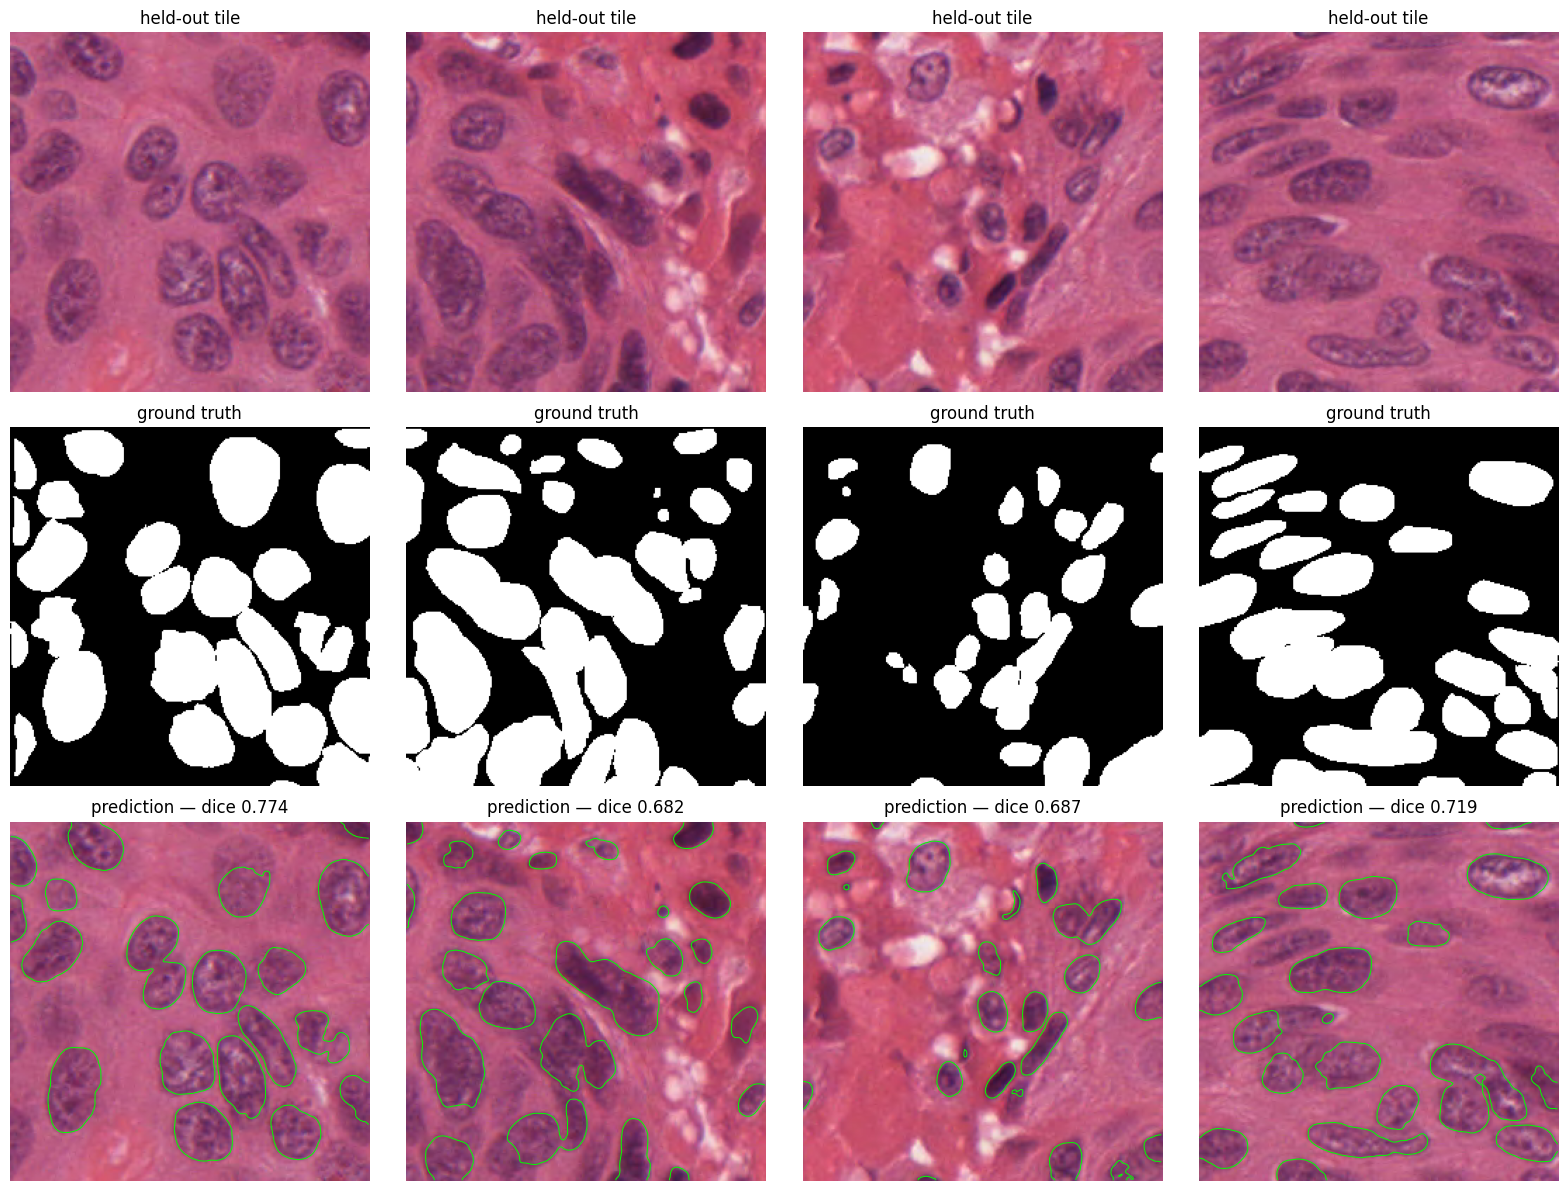

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
xb, yb = next(iter(val_ds))
pred = model.predict(xb, verbose=0)

fig, ax = plt.subplots(3, 4, figsize=(16, 12))
for k in range(4):
    raw = (xb[k].numpy() + 1) / 2
    ax[0, k].imshow(raw); ax[0, k].set_title("held-out tile")
    ax[1, k].imshow(yb[k, :, :, 0], cmap="gray"); ax[1, k].set_title("ground truth")
    ax[2, k].imshow(raw)
    ax[2, k].contour(pred[k, :, :, 0], levels=[0.5], colors="lime", linewidths=0.7)
    d = dice_coef(yb[k:k+1], pred[k:k+1])
    ax[2, k].set_title(f"prediction — dice {float(d):.3f}")

for a in ax.ravel():
    a.axis("off")

plt.tight_layout()
plt.savefig("predictions.png", dpi=120, bbox_inches="tight")
plt.show()

files.download("predictions.png")

## 6. Instance separation with watershed

The U-Net outputs a binary mask, and where two nuclei touch they fuse into one
connected region. Counting connected components therefore undercounts.

The model's probability map actually contains the information - confidence dips at
the shared boundary - but thresholding at 0.5 discards it. Watershed recovers the
separation: the distance transform gives each foreground pixel its distance to the
nearest background pixel, producing one peak per nucleus with a low ridge between
touching pairs. Flooding outward from those peaks puts the boundary on the ridge.

This is also why Dice alone is misleading here. A merged pair covers almost exactly
the right pixels, so Dice barely moves while the object count is wrong.

`min_distance` is swept below across 8 validation tiles. Note this means it is
tuned on the validation set - one parameter from five options, but not a fully
clean held-out measurement.

In [35]:
!pip install -q scikit-image

from skimage.segmentation import watershed
from skimage.feature import peak_local_max
from scipy import ndimage as ndi

def split_instances(prob, thresh=0.5, min_distance=5):
    mask = prob > thresh
    distance = ndi.distance_transform_edt(mask)
    peaks = peak_local_max(distance, min_distance=min_distance, labels=mask)
    markers = np.zeros(distance.shape, np.int32)
    markers[tuple(peaks.T)] = np.arange(1, len(peaks) + 1)
    return watershed(-distance, markers, mask=mask)

labels_ws = split_instances(pred[0, :, :, 0])
labels_cc, n_cc = ndi.label(pred[0, :, :, 0] > 0.5)

print("connected components:", n_cc)
print("after watershed:", labels_ws.max())
print("ground truth nuclei in this tile:", len(np.unique(tile_inst[val_idx[0]])) - 1)

connected components: 19
after watershed: 26
ground truth nuclei in this tile: 28


In [36]:
for md in [2, 3, 4, 5, 7]:
    counts = [split_instances(pred[k, :, :, 0], min_distance=md).max() for k in range(8)]
    truth = [len(np.unique(tile_inst[val_idx[k]])) - 1 for k in range(8)]
    err = np.mean([abs(c - t) / t for c, t in zip(counts, truth)])
    print(f"min_distance={md}  counted={sum(counts)}  truth={sum(truth)}  mean abs error={err:.1%}")

min_distance=2  counted=518  truth=269  mean abs error=93.8%
min_distance=3  counted=354  truth=269  mean abs error=32.8%
min_distance=4  counted=295  truth=269  mean abs error=15.1%
min_distance=5  counted=251  truth=269  mean abs error=10.0%
min_distance=7  counted=221  truth=269  mean abs error=16.9%


connected components error: 26.7%
watershed error:           10.0%


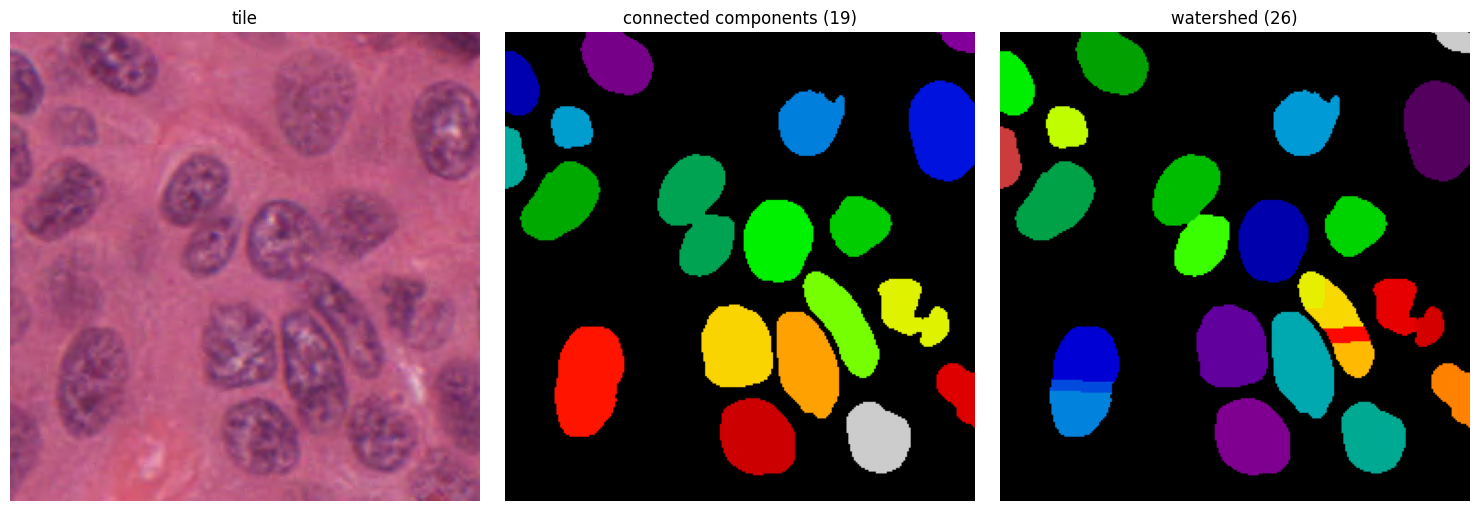

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
md = 5
counts = [split_instances(pred[k, :, :, 0], min_distance=md).max() for k in range(8)]
cc = [ndi.label(pred[k, :, :, 0] > 0.5)[0].max() for k in range(8)]
truth = [len(np.unique(tile_inst[val_idx[k]])) - 1 for k in range(8)]

print("connected components error:", f"{np.mean([abs(c - t) / t for c, t in zip(cc, truth)]):.1%}")
print("watershed error:          ", f"{np.mean([abs(c - t) / t for c, t in zip(counts, truth)]):.1%}")

from skimage.color import label2rgb

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow((xb[0].numpy() + 1) / 2); ax[0].set_title("tile")
ax[1].imshow(ndi.label(pred[0, :, :, 0] > 0.5)[0], cmap="nipy_spectral"); ax[1].set_title(f"connected components ({cc[0]})")
ax[2].imshow(split_instances(pred[0, :, :, 0], min_distance=md), cmap="nipy_spectral"); ax[2].set_title(f"watershed ({counts[0]})")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig("watershed.png", dpi=120, bbox_inches="tight"); plt.show()

files.download("watershed.png")